In [24]:
import io
from typing import List

import pandas as pd
from PIL import Image
from matplotlib import pyplot as plt

from homework_3.classes import ApiResponsesDataset
from homework_3.classes import ClipModel

In [2]:
WEIGHTS_HEAD1 = "../weights/concept1_25_2.pth"
WEIGHTS_HEAD2 = "../weights/concept2_25_2.pth"

clip_model = ClipModel()

df = pd.read_parquet("../datasets/cifar100_train.parquet")
series = df.img[:100]

dataset = ApiResponsesDataset(clip_model.preprocess, img_series=series)

In [34]:
class ImageContainer:
    def __init__(self, img: Image.Image, score: float, index: int):
        self.img = img
        self.score = score
        self.index = index

    def __lt__(self, other):
        return self.score < other.score

    def __eq__(self, value: object, /) -> bool:
        return self.score == value

In [25]:
top_scores = [[], [], [], []]

for i in range(len(dataset)):
    data, label = dataset[i]
    for j in range(4):
        output_value = label[j]
        if len(top_scores[j]) < 4:
            top_scores[j].append(output_value)
        else:
            min_top_score = min(top_scores[j])
            if output_value > min_top_score:
                top_scores[j].remove(min_top_score)
                top_scores[j].append(output_value)

print(top_scores)


[[tensor(0.9719), tensor(0.8996), tensor(0.9037), tensor(0.9236)], [tensor(0.9983), tensor(0.9995), tensor(0.9998), tensor(0.9988)], [tensor(0.9613), tensor(0.9700), tensor(0.9613), tensor(0.9669)], [tensor(0.9150), tensor(0.8982), tensor(0.8379), tensor(0.9759)]]


In [28]:
top_scores: List[List[ImageContainer]] = [[], [], [], []]
series_len = 1_000

for i in range(series_len):
    image = Image.open(io.BytesIO(df.img[i]['bytes']))
    data = clip_model.preprocess(image).unsqueeze(0)
    data = data.cuda()
    output = clip_model(data)[0]
    for j in range(4):
        output_value = output[j]
        imgC = ImageContainer(image, output_value, i)
        if len(top_scores[j]) < 5:
            top_scores[j].append(imgC)
        else:
            min_top_score = min(top_scores[j])
            if imgC > min_top_score:
                top_scores[j].remove(min_top_score)
                top_scores[j].append(imgC)
    if (i + 1) % 100 == 0:
        print(f"{i + 1}/{series_len}")



99/1000
199/1000
299/1000
399/1000
499/1000
599/1000
699/1000
799/1000
899/1000
999/1000


Top scores for class1


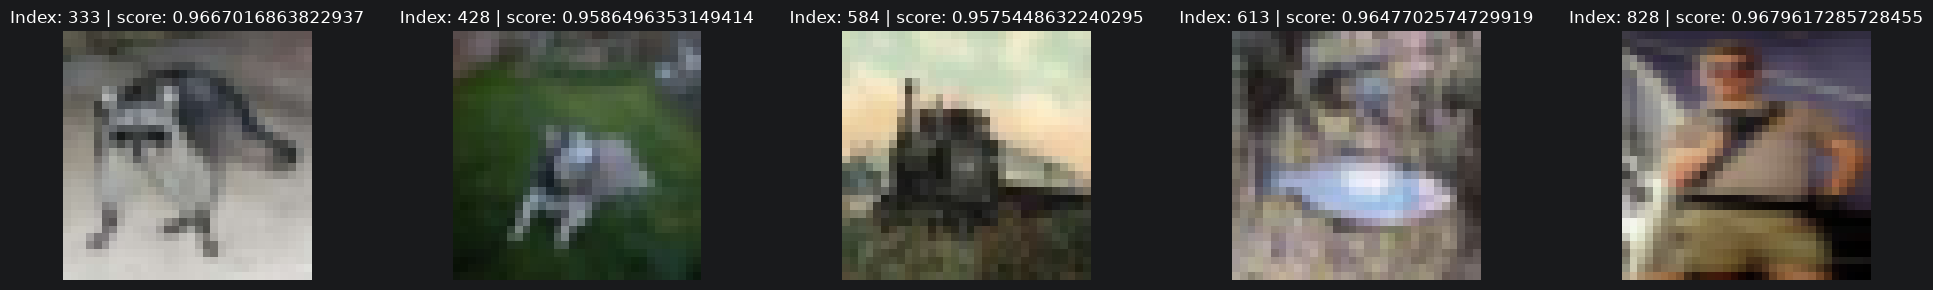

Top scores for class2


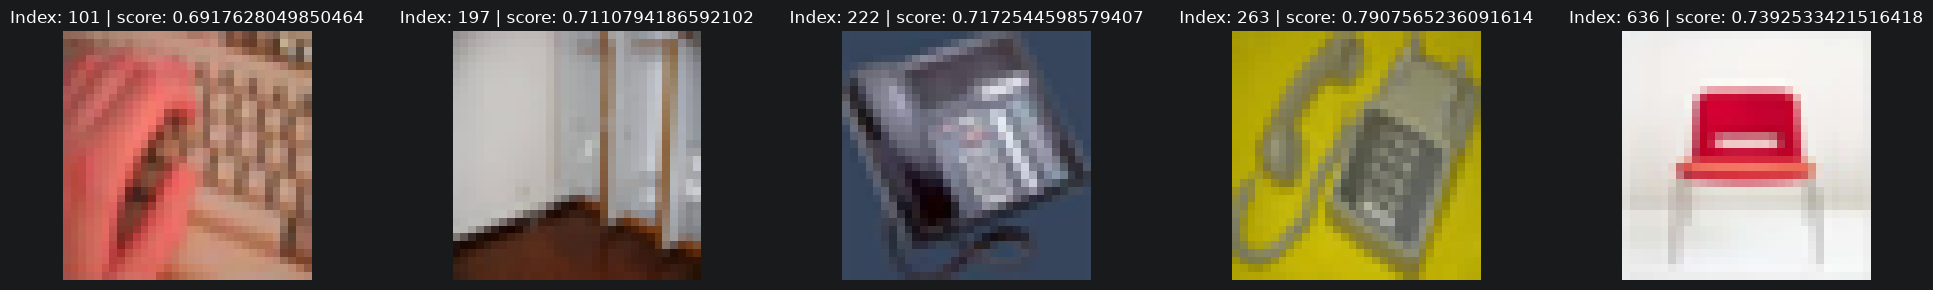

Top scores for class3


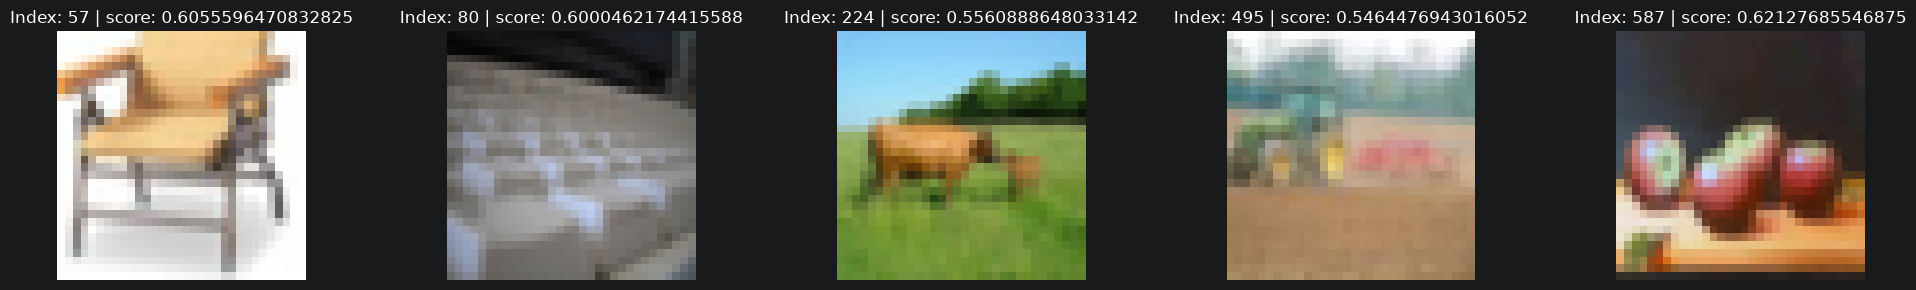

Top scores for class4


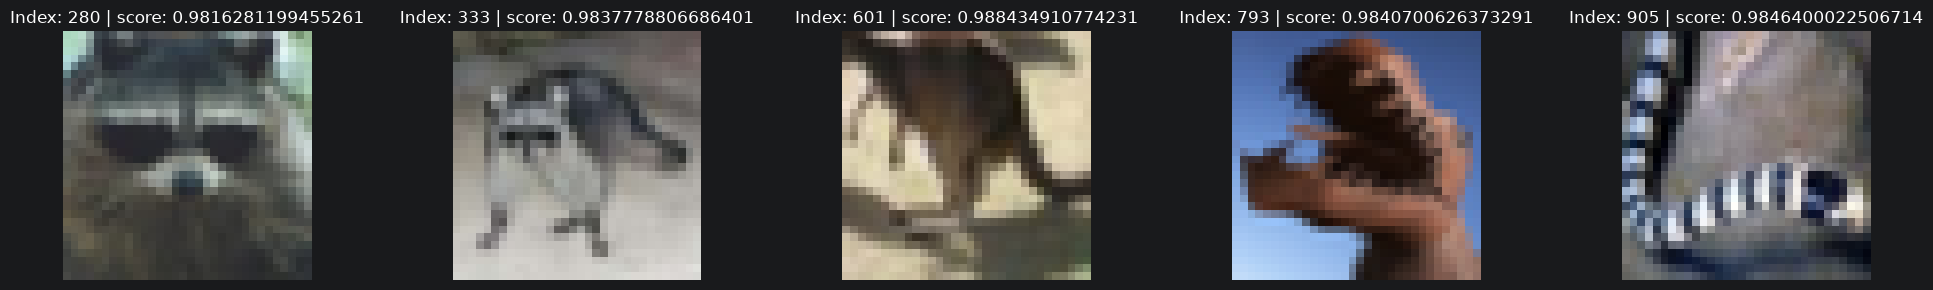

In [33]:
for i in range(4):
    print(f"Top scores for class{i+1}")
    cl = top_scores[i]
    fig, axes = plt.subplots(1, 5, figsize=(20, 3))

    for j in range(5):
        imgC = cl[j]

        axes[j].imshow( imgC.img, cmap="gray")
        axes[j].set_title(f"Index: {imgC.index} | score: {imgC.score}")
        axes[j].axis("off")

    plt.tight_layout()
    plt.show()